# Polymer dynamics with varying strain rate

First run the example to train and save the trained model
```shell
cd ./examples/UIDD_polymer_dynamics_wi
python I2_polymer_dynamics_wi.py
```

The results will be saved to a path in `./outputs/...` that appropriately time-stamped.

The rest of the notebook will perform analysis on the outputs.

In [5]:
import os

# Check and remove LD_LIBRARY_PATH if present
if 'LD_LIBRARY_PATH' in os.environ:
    print(f"Found LD_LIBRARY_PATH: {os.environ['LD_LIBRARY_PATH']}")
    del os.environ['LD_LIBRARY_PATH']
    print("✅ Removed LD_LIBRARY_PATH")
else:
    print("✅ LD_LIBRARY_PATH not set (good)")

# Deleting LD_LIBRARY_PATH above does not affect this kernel: the dynamic loader read it
# at process start. The pip libcusparse (CUDA 12.9) would still bind the older
# /usr/local/cuda (12.8) libnvJitLink, fail to load, and JAX would fall back to CPU.
# Preload the env's own libnvJitLink so cuSPARSE resolves to it.
import ctypes, glob, nvidia
for lib in glob.glob(os.path.join(nvidia.__path__[0], "nvjitlink", "lib", "libnvJitLink.so.*")):
    ctypes.CDLL(lib, mode=ctypes.RTLD_GLOBAL)

os.environ['JAX_PLATFORMS'] = ''
os.environ['CUDA_VISIBLE_DEVICES'] = '2'
os.environ['HF_HOME'] = "~/nfs/hf_cache" 

import jax
jax.config.update("jax_enable_x64", True)
print(jax.devices())

import jax.numpy as jnp
import jax.random as jr
import equinox as eqx
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme()
import numpy as np
from tqdm.auto import tqdm

✅ LD_LIBRARY_PATH not set (good)
[CpuDevice(id=0)]


## Read saved model and config

In [6]:
from omegaconf import OmegaConf
from I2_polymer_dynamics_wi import build_model
from datasets import load_dataset
path = "outputs/2026_02_14-15_31_11" 
config = OmegaConf.load(os.path.join(path, ".hydra/config.yaml"))
model_template = build_model(config) 
trained_model = eqx.tree_deserialise_leaves(os.path.join(path, "model.eqx"), model_template)

## Predictions

In [7]:
from datasets import load_from_disk

In [8]:
# data_cache_nolog is gitignored and not in this checkout; the only copy is in PhaseDiagram_save0
DATA_ROOT = "/home/aiqing/nfs/PhaseDiagram_save0/examples/UIDD_polymer_dynamics_wi"
test_data_name = os.path.join(DATA_ROOT, config.data.cache_path, config.data.filename+"_test")
test_data = load_from_disk(test_data_name).with_format("numpy")
print(f"loaded: {test_data_name}")

loaded: /home/aiqing/nfs/PhaseDiagram_save0/examples/UIDD_polymer_dynamics_wi/data_cache_nolog/reduced_symm_new_test


Analyse trajectory statistics

In [9]:
from examples.utils.sde import SDEIntegrator
integrator = SDEIntegrator(model=trained_model, state_dim=config.dim)

Helper functions

In [10]:
@jax.jit
def compute_unfolding_time(traj):
    unfolded_extension = traj[:, -1, 0]
    threshold = 0.95 * unfolded_extension
    first_index = jnp.argmin(traj[:, :, 0] <= threshold[:, None], axis=1)
    return first_index

In [11]:
dt = (test_data["Wi0_5_T1_fast"][0]["t"][1] - test_data["Wi0_5_T1_fast"][0]["t"][0])[0].astype("float64")

In [12]:
dt

np.float64(0.0005000000237487257)

In [13]:
def compare_statistics(test_data, test_split, key, return_results=False, args_override=None):

    # Extract data
    test_data_fast = test_data[f"{test_split}_fast"]
    test_data_medium = test_data[f"{test_split}_middle"]
    test_data_slow = test_data[f"{test_split}_slow"]

    # Convert to numpy arrays to support slice indexing
    test_x = [
        jnp.array(test_data_fast["x"]),
        jnp.array(test_data_medium["x"]),
        jnp.array(test_data_slow["x"])
    ]

    # Extract args correctly - they should be (2,) arrays
    test_args = [
        jnp.array(test_data_fast["args"])[0, 0],  # Extract the first args and ensure it's (2,)
        jnp.array(test_data_medium["args"])[0, 0],
        jnp.array(test_data_slow["args"])[0, 0]
    ]

    # Generate predicted trajectories
    keys = jr.split(key, 3)
    predicted_trajectories = []

    for i, (key, traj, args) in enumerate(zip(keys, test_x, test_args)):

        num_runs = traj.shape[0]
        traj_len = traj.shape[1]

        if args_override is not None:
            args = args_override

        init_conditions = jnp.repeat(traj[0, 0, :][None, :], num_runs, axis=0)
        bm_keys = jr.split(key, num_runs)

        # Use num_steps instead of t1 to avoid floating point precision issues
        num_steps = traj_len - 1  # Number of intervals (not points)

        sol = integrator.parallel_solve(
            key=bm_keys,
            initial_conditions=init_conditions,
            t0=0.0,
            t1=None,  # Will be computed as t0 + num_steps * dt
            dt=dt,
            args=args,
            num_steps=num_steps,  # This ensures exact length matching
        )

        predicted_trajectories.append(sol.ys)

    if return_results:
        return {"true_trajectories": test_x,
                "predicted_trajectories": predicted_trajectories,
                "args": test_args}

Compare statistics

In [14]:
def compare_all_statistics_combined(test_data, keys):
    """Create one large combined plot comparing all test splits and conditions"""

    test_splits = list(set(k.rsplit('_', 1)[0] for k in test_data.keys()))
    n_splits = len(test_splits)

    # Create a large figure with square aspect ratio: each subplot should be approximately square
    # 9 columns (3 conditions × 3 metrics), make height proportional to maintain square subplots
    subplot_size = 4  # Size of each subplot
    fig_width = 9 * subplot_size  # 9 columns
    fig_height = n_splits * subplot_size  # n_splits rows

    fig, axes = plt.subplots(n_splits, 9, figsize=(fig_width, fig_height), layout="constrained")

    # If only one split, make sure axes is 2D
    if n_splits == 1:
        axes = axes[None, :]

    # Collect all results first
    all_results = {}
    for i, (key, test_split) in enumerate(zip(keys, test_splits)):
        result = compare_statistics(test_data, test_split, key, return_results=True)
        all_results[test_split] = result

    # Now plot everything in the combined figure
    for i, test_split in enumerate(test_splits):
        result = all_results[test_split]
        true_trajs = result["true_trajectories"]
        pred_trajs = result["predicted_trajectories"]

        # For each condition (Fast, Medium, Slow)
        condition_names = ["Fast", "Medium", "Slow"]
        for j, (condition, true, pred) in enumerate(zip(condition_names, true_trajs, pred_trajs)):

            # Calculate statistics
            true_mean = jnp.mean(true, axis=0)
            pred_mean = jnp.mean(pred, axis=0)
            true_std = jnp.std(true, axis=0)
            pred_std = jnp.std(pred, axis=0)
            true_unfolding = compute_unfolding_time(true)
            pred_unfolding = compute_unfolding_time(pred)

            # Plot mean (column 0, 3, 6)
            col_idx = j * 3 + 0
            axes[i, col_idx].plot(true_mean[:, 0], label="True", alpha=0.8)
            axes[i, col_idx].plot(pred_mean[:, 0], label="Pred", alpha=0.8)
            axes[i, col_idx].set_title(f"{condition} - Mean")
            axes[i, col_idx].legend()
            axes[i, col_idx].grid(True, alpha=0.3)

            # Plot std (column 1, 4, 7)
            col_idx = j * 3 + 1
            axes[i, col_idx].plot(true_std[:, 0], label="True", alpha=0.8)
            axes[i, col_idx].plot(pred_std[:, 0], label="Pred", alpha=0.8)
            axes[i, col_idx].set_title(f"{condition} - Std Dev")
            axes[i, col_idx].legend()
            axes[i, col_idx].grid(True, alpha=0.3)

            # Plot unfolding time (column 2, 5, 8)
            col_idx = j * 3 + 2
            axes[i, col_idx].hist(true_unfolding, label="True", alpha=0.6, density=True, bins=15)
            axes[i, col_idx].hist(pred_unfolding, label="Pred", alpha=0.6, density=True, bins=15)
            axes[i, col_idx].set_title(f"{condition} - Unfolding Time")
            axes[i, col_idx].legend()
            axes[i, col_idx].grid(True, alpha=0.3)

        # Add row label (test split name)
        axes[i, 0].set_ylabel(f"{test_split}\nExtension", fontsize=12, fontweight='bold')

    # Add column labels at the top
    col_labels = ["Fast Mean", "Fast Std", "Fast Unfold",
                  "Medium Mean", "Medium Std", "Medium Unfold",
                  "Slow Mean", "Slow Std", "Slow Unfold"]
    for j, label in enumerate(col_labels):
        axes[0, j].set_title(label, fontsize=12, fontweight='bold')

    # Set x-labels only on bottom row
    for j in range(9):
        if j % 3 == 2:  # Unfolding time columns
            axes[-1, j].set_xlabel("Time Steps")
        else:  # Mean and std columns
            axes[-1, j].set_xlabel("Time")

    plt.suptitle("Combined Statistics Comparison Across All Conditions", fontsize=16, y=0.98)
    plt.tight_layout()
    plt.show()

    return all_results

Creating combined plot for 10 test splits...


/tmp/ipykernel_528699/2646729734.py:85: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


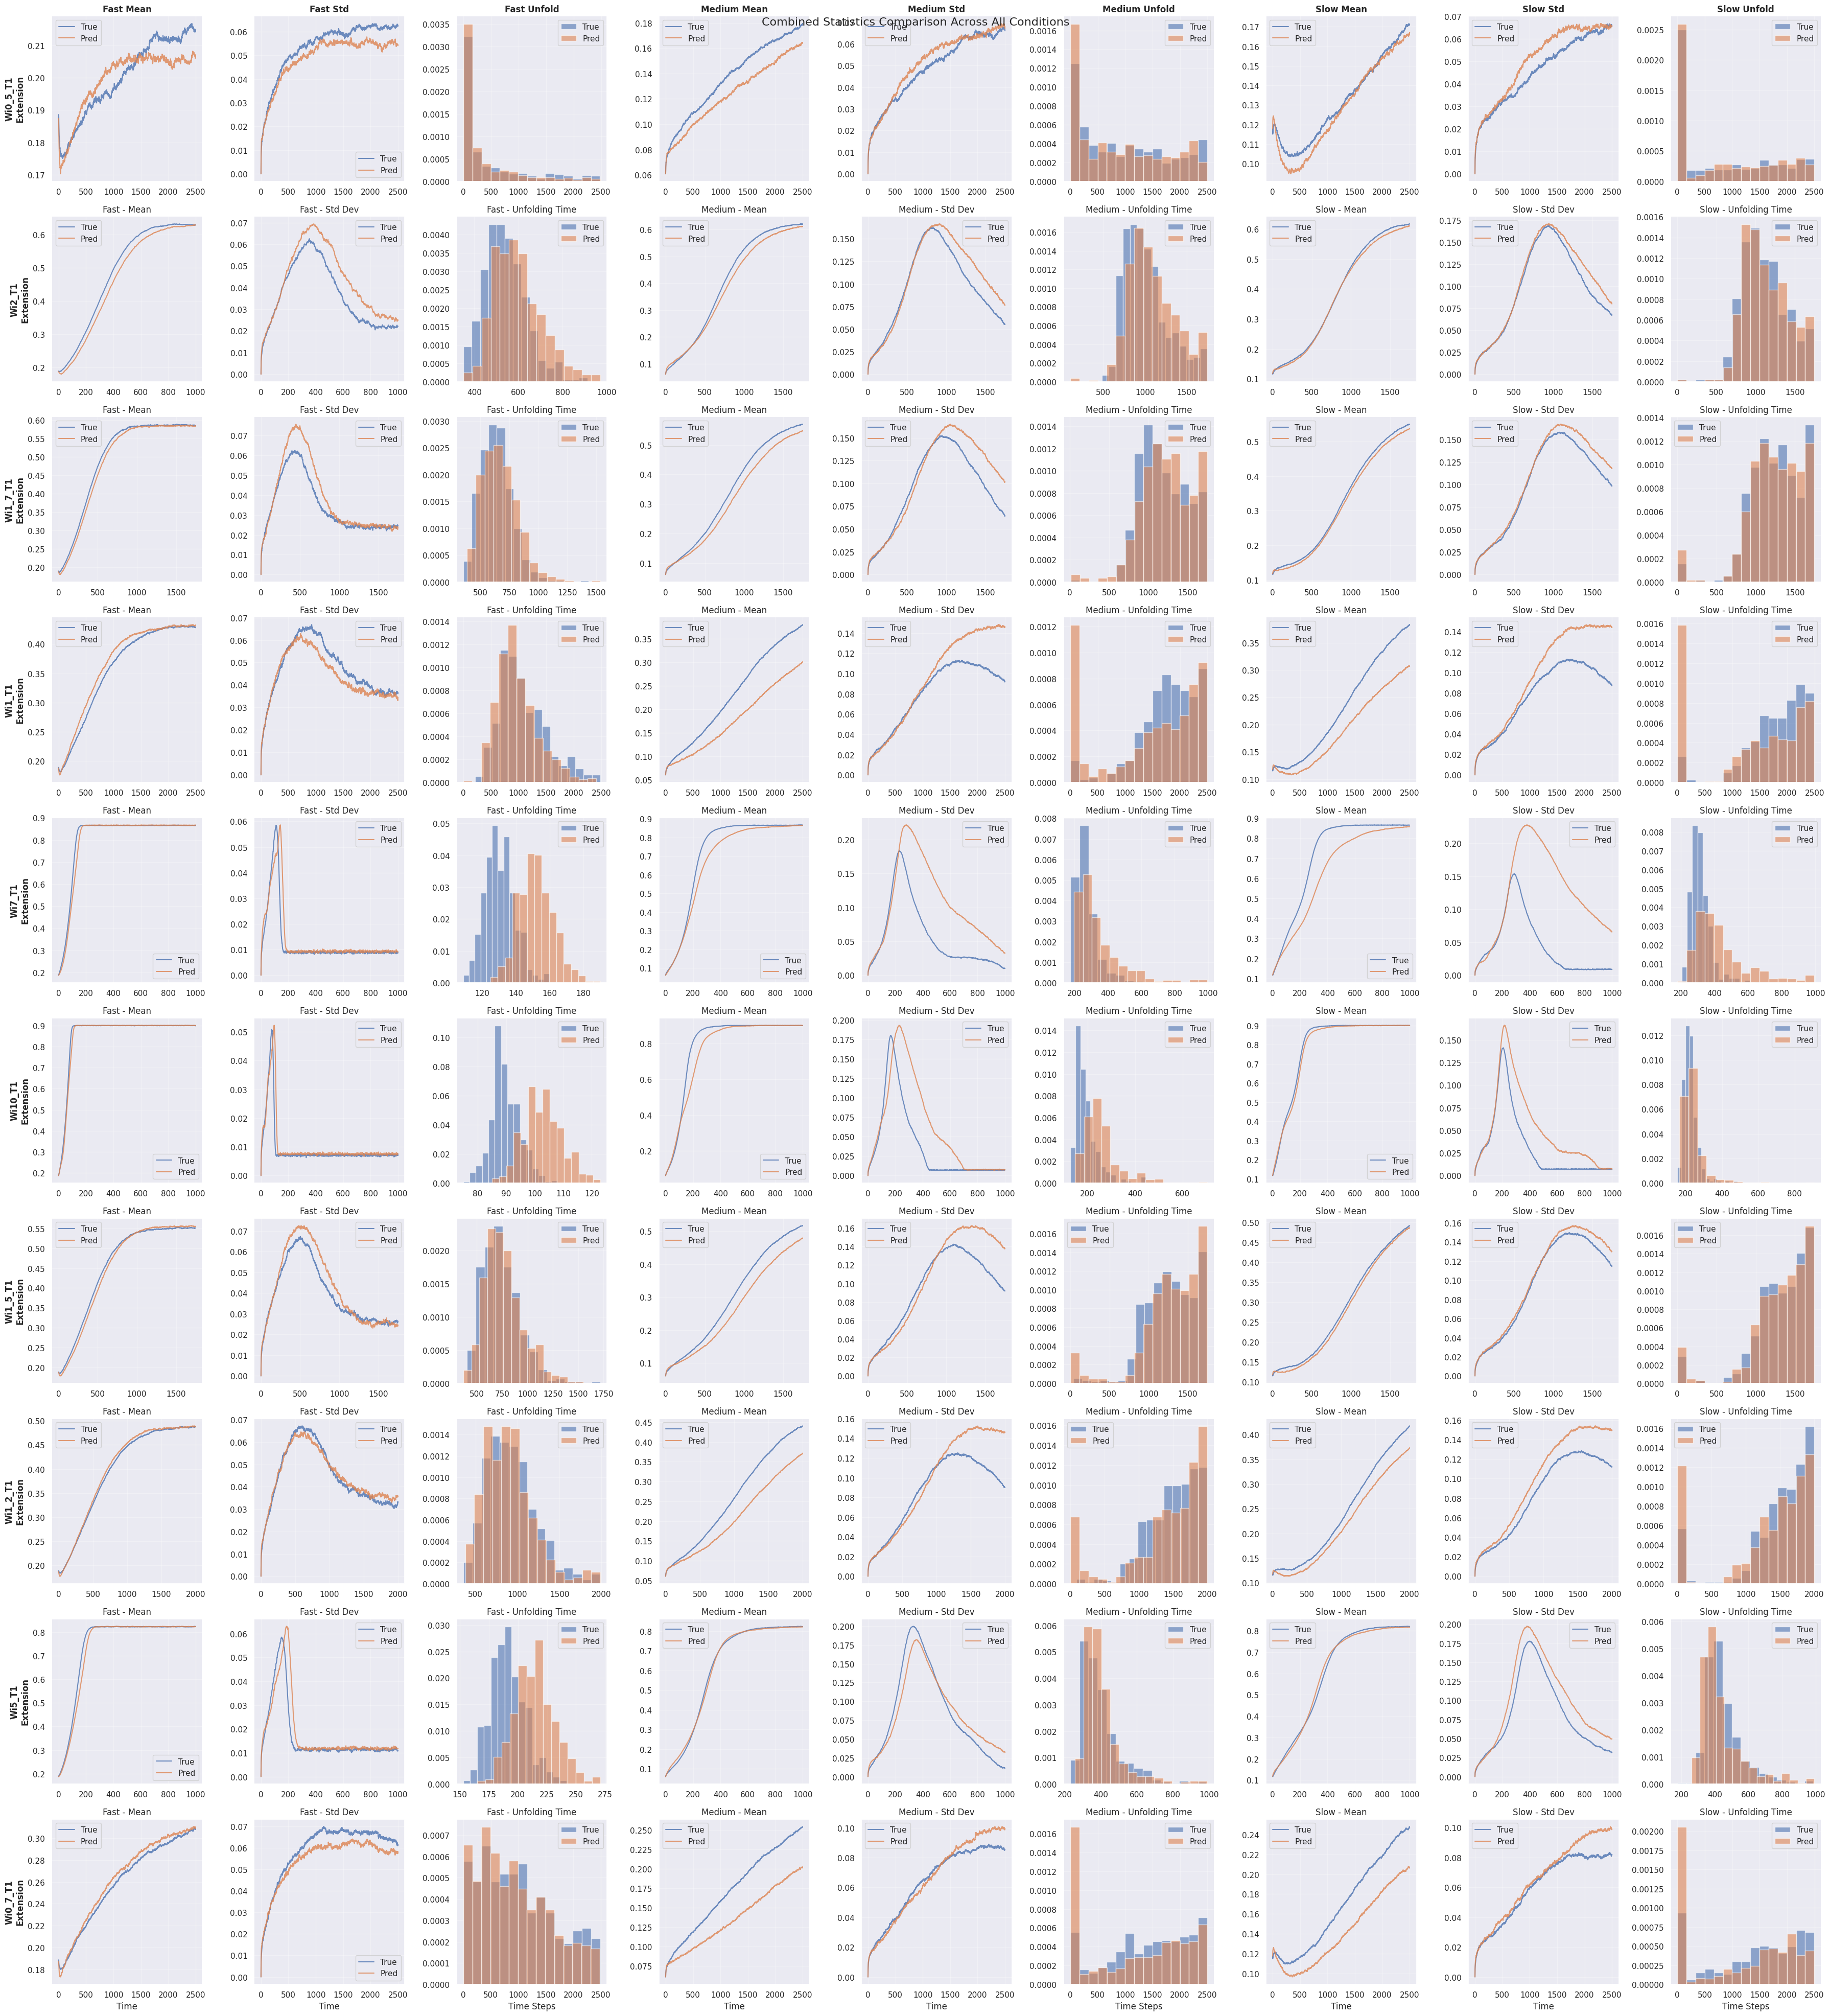

In [15]:
# Generate the combined plot
test_splits = set(k.rsplit('_', 1)[0] for k in test_data.keys())
keys = jr.split(jr.PRNGKey(config.model.seed + 123), len(test_splits))

print(f"Creating combined plot for {len(test_splits)} test splits...")
all_results = compare_all_statistics_combined(test_data, keys)

In [19]:
# Save the data behind the combined figure above. Reads all_results, so nothing is re-simulated.
# The figure's row order is the order of all_results; it comes from a set, so a new kernel may
# give a different order (and pair different PRNG keys with the splits) -- hence "splits" below.
save_path = f"symm_analysis_stats_{os.path.basename(path)}.npz"
conditions = ["fast", "middle", "slow"]   # figure columns Fast / Medium / Slow
plot_data = {
    "model_path": path,
    "dt": dt,
    "key_seed": config.model.seed + 123,
    "splits": np.array(list(all_results.keys())),   # figure rows, top to bottom
    "conditions": np.array(conditions),
}
for split, result in all_results.items():
    for cond, true, pred, args in zip(conditions, result["true_trajectories"],
                                      result["predicted_trajectories"], result["args"]):
        true, pred = np.asarray(true), np.asarray(pred)
        p = f"{split}_{cond}/"
        plot_data[p + "args"] = np.asarray(args)
        plot_data[p + "t"] = np.arange(true.shape[1]) * dt
        plot_data[p + "true_mean"] = true.mean(axis=0)   # (T, 3); the figure plots [:, 0]
        plot_data[p + "pred_mean"] = pred.mean(axis=0)
        plot_data[p + "true_std"] = true.std(axis=0)
        plot_data[p + "pred_std"] = pred.std(axis=0)
        plot_data[p + "true_unfold_step"] = np.asarray(compute_unfolding_time(true))   # (N,), histogrammed
        plot_data[p + "pred_unfold_step"] = np.asarray(compute_unfolding_time(pred))
np.savez_compressed(save_path, **plot_data)
print(f"saved {len(plot_data)} arrays -> {save_path}")

saved 245 arrays -> symm_analysis_stats_2026_02_14-15_31_11.npz


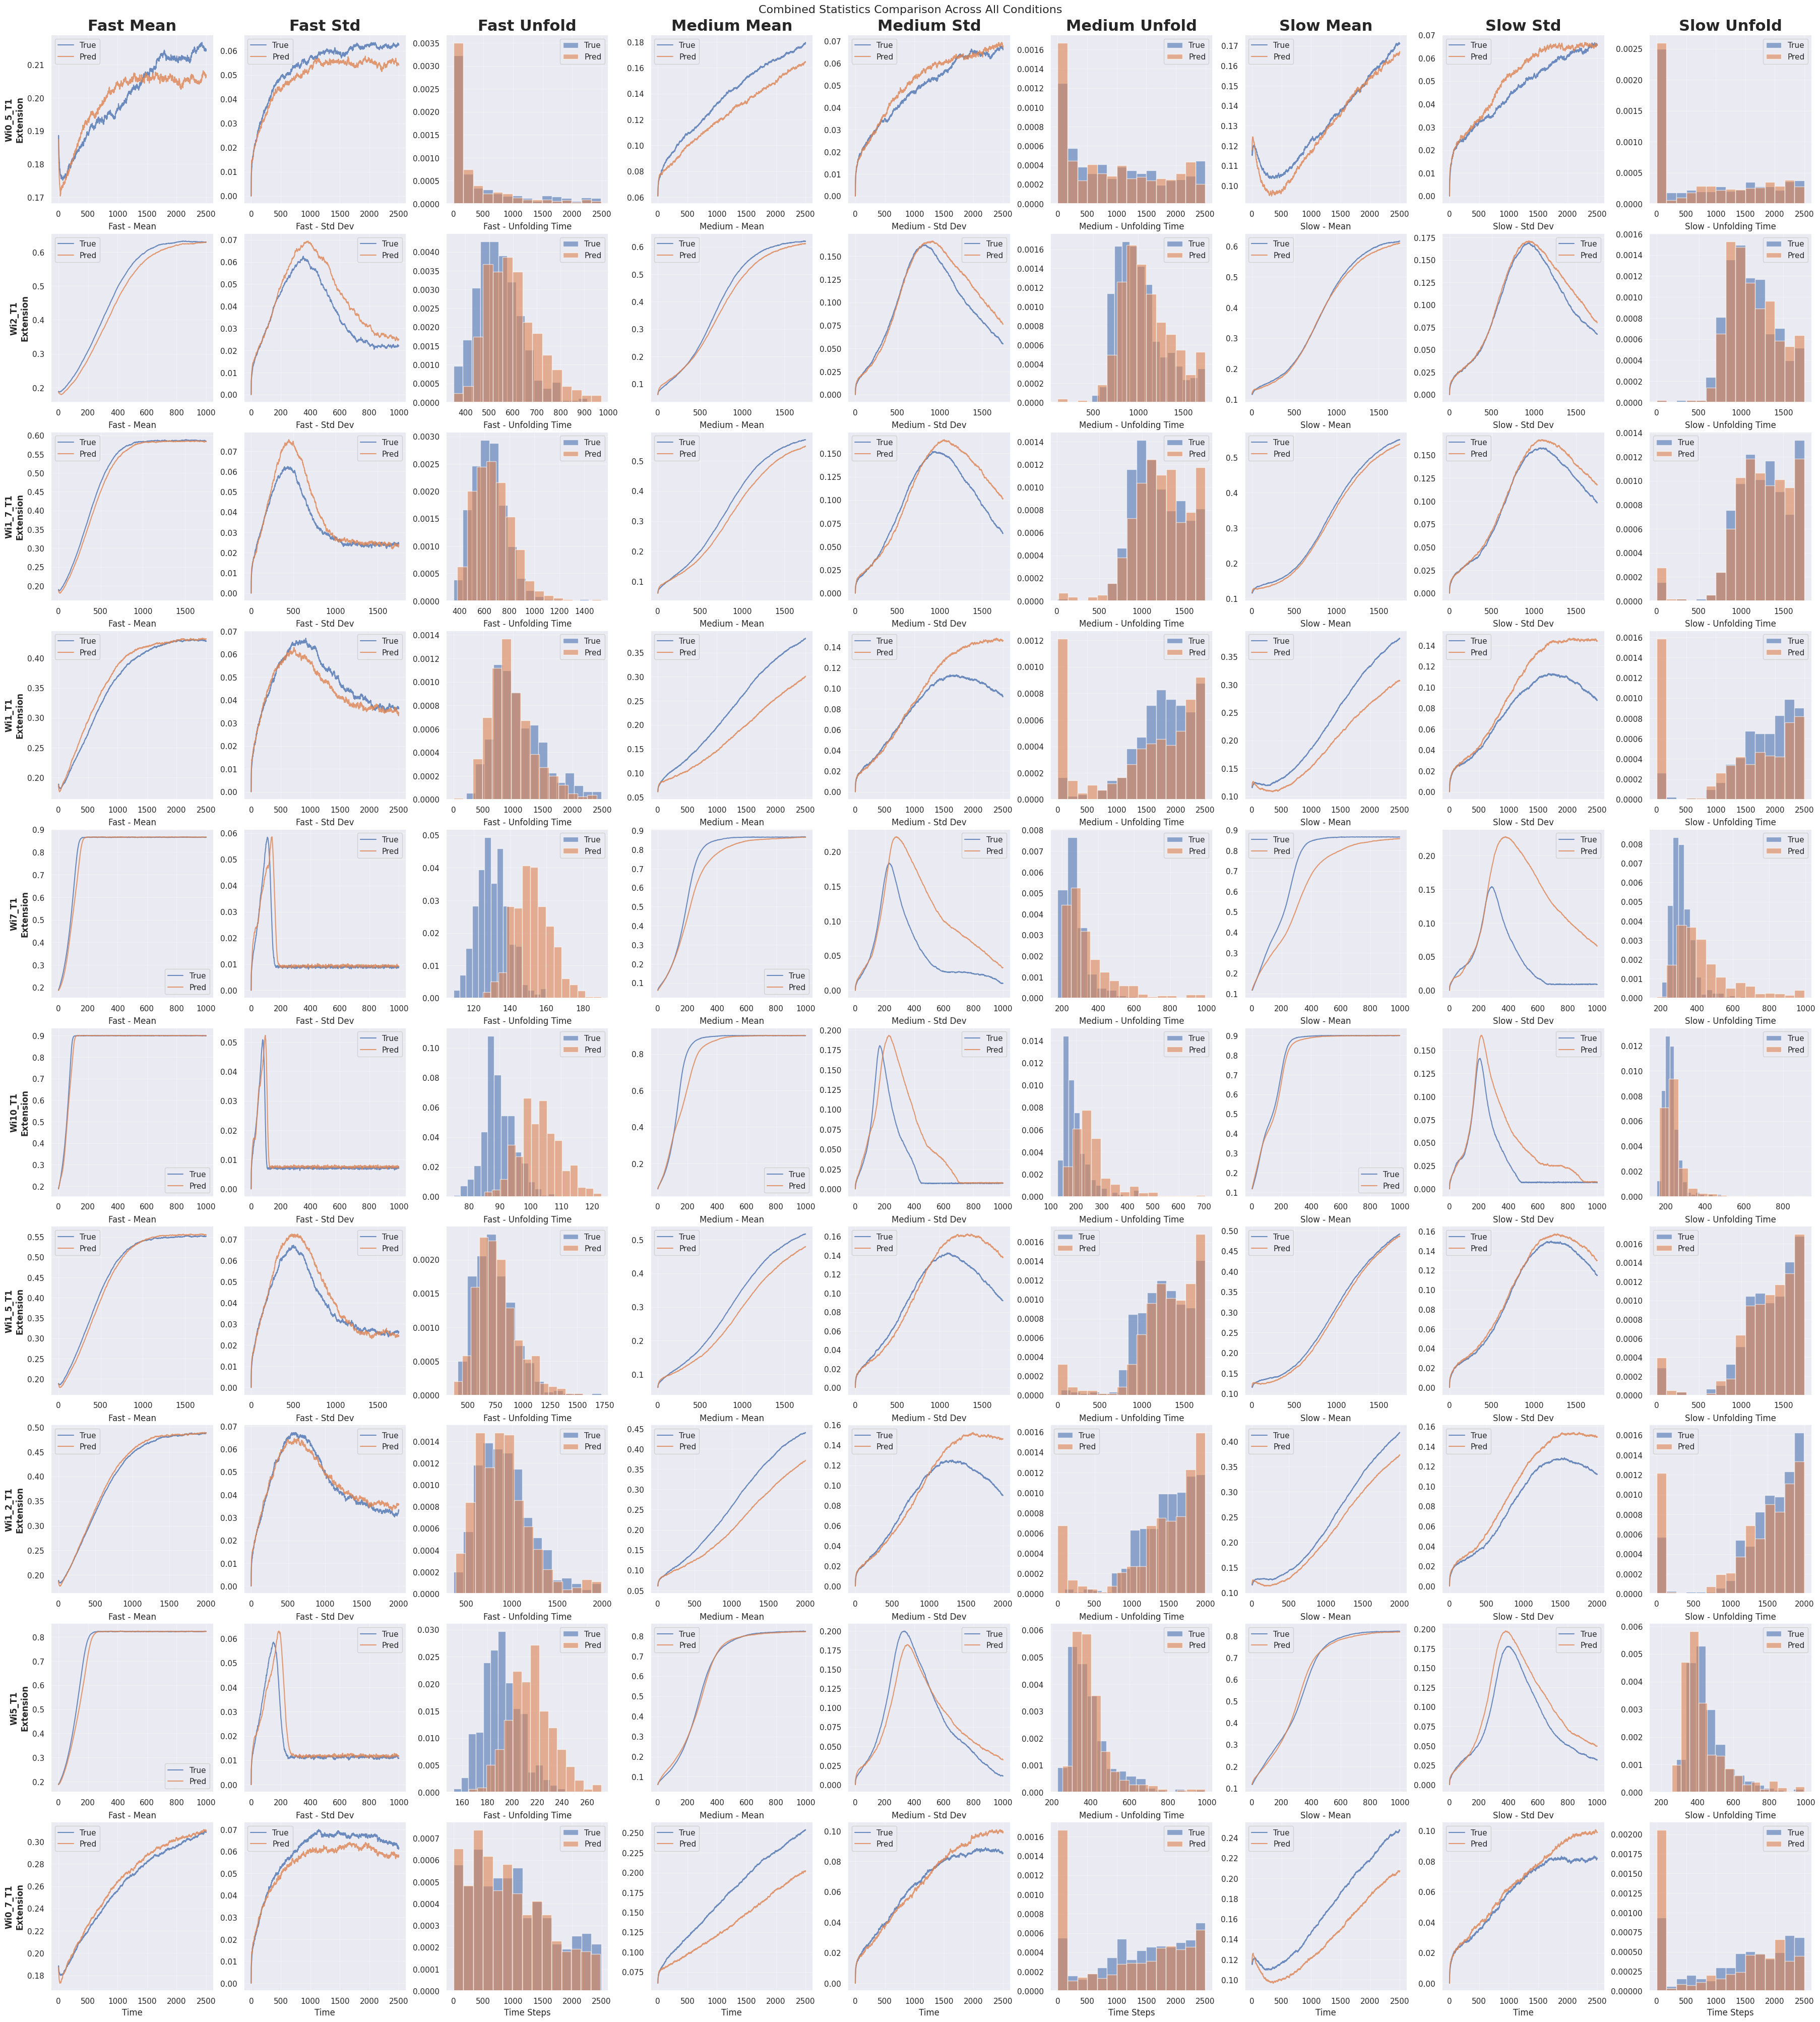

In [22]:
# Redraw the combined figure from the npz saved above. Needs none of the earlier cells,
# so it also runs on its own in a fresh kernel (no model, data or simulation needed).
import numpy as np
import matplotlib.pyplot as plt 

plot_file = "symm_analysis_stats_2026_02_14-15_31_11.npz"
d = np.load(plot_file)
splits = list(d["splits"])            # rows, in the order of the original figure
conditions = list(d["conditions"])    # fast / middle / slow
cond_names = ["Fast", "Medium", "Slow"]

fig, axes = plt.subplots(len(splits), 9, figsize=(9 * 4, len(splits) * 4),
                         squeeze=False, layout="constrained")   # constrained layout makes room for the suptitle
for i, split in enumerate(splits):
    for j, (cond, name) in enumerate(zip(conditions, cond_names)):
        p = f"{split}_{cond}/"
        ax_mean, ax_std, ax_unf = axes[i, 3 * j : 3 * j + 3]
        # x is the step index, as in the original; use d[p + "t"] to plot against time
        for ax, stat in ((ax_mean, "mean"), (ax_std, "std")):
            ax.plot(d[p + f"true_{stat}"][:, 0], label="True", alpha=0.8)
            ax.plot(d[p + f"pred_{stat}"][:, 0], label="Pred", alpha=0.8)
        ax_unf.hist(d[p + "true_unfold_step"], label="True", alpha=0.6, density=True, bins=15)
        ax_unf.hist(d[p + "pred_unfold_step"], label="Pred", alpha=0.6, density=True, bins=15)
        for ax, metric in zip((ax_mean, ax_std, ax_unf), ("Mean", "Std Dev", "Unfolding Time")):
            ax.set_title(f"{name} - {metric}")
            ax.legend()
            ax.grid(True, alpha=0.3)
    axes[i, 0].set_ylabel(f"{split}\nExtension", fontsize=12, fontweight="bold")

col_labels = [f"{n} {m}" for n in cond_names for m in ("Mean", "Std", "Unfold")]
for j, label in enumerate(col_labels):
    axes[0, j].set_title(label, fontsize=22, fontweight="bold")
for j in range(9):
    axes[-1, j].set_xlabel("Time Steps" if j % 3 == 2 else "Time")

fig.suptitle("Combined Statistics Comparison Across All Conditions", fontsize=16)
fig.savefig(plot_file.replace(".npz", ".png"), dpi=100)
plt.show()